# 03 Automated run: exceptions report and timing

**Business question.** How long does a full review cycle take once the checks are automated, and what does the reviewer receive at the end of it?

This notebook runs the whole pipeline end to end (extract, validate, load, nine checks, consolidated exceptions report), writes the exceptions report to `data/processed/exceptions_report.csv`, and measures:

* **Review run time** of the automated cycle, compared with the office's manual review baseline.
* **Latency** of the monthly refresh: the time from a new month's extract landing to the exceptions report being ready, comparing a full rebuild from all historical files with the incremental load in `etl.append_extract`.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=["#2a6fb0", "#e0702b", "#2e9e6b", "#c9a227", "#8a5cc2", "#d0475a", "#5a6b7b", "#3fb3c4"]),
})

In [2]:
import shutil
from etl import run_etl, append_extract, connect, DB_PATH
from checks import run_all_checks, build_exceptions_report, CHECK_DESCRIPTIONS, CHECK_WEIGHTS

def automated_review(full_rebuild=True, raw_dir=RAW, db_path=DB_PATH, new_extract=None, out_csv=None):
    """One review cycle. Returns (exceptions report, timing dict)."""
    t0 = time.perf_counter()
    etl = run_etl(raw_dir, db_path) if full_rebuild else append_extract(new_extract, db_path, raw_dir)
    t1 = time.perf_counter()
    conn = connect(db_path)
    results, check_timing = run_all_checks(conn)
    t2 = time.perf_counter()
    report = build_exceptions_report(conn, results)
    if out_csv is not None:
        report.to_csv(out_csv, index=False)
    conn.close()
    t3 = time.perf_counter()
    return report, results, {"etl_s": t1 - t0, "checks_s": t2 - t1, "report_s": t3 - t2, "total_s": t3 - t0}

## 1. Full automated run

Everything from the raw extracts to the CSV the reviewer opens.

In [3]:
report, results, t_full = automated_review(full_rebuild=True, out_csv=PROC / "exceptions_report.csv")
print({k: round(v, 2) for k, v in t_full.items()})
print(f"Exceptions report: {len(report):,} transactions, ${report.amount.sum():,.0f}")

{'etl_s': 5.65, 'checks_s': 4.65, 'report_s': 2.2, 'total_s': 12.5}
Exceptions report: 6,067 transactions, $49,963,530


## 2. The exceptions report

One row per flagged transaction, with every check it failed, a weighted risk score (duplicate payments, self-approval and new-vendor payments weigh most) and the context a reviewer needs. Rows are ranked so the reviewer starts with the transactions that fail several high-severity checks.

In [4]:
report.head(10)[["priority_rank", "txn_id", "checks_failed", "risk_score", "posting_date", "vendor_name",
                  "dept_name", "amount"]]

,priority_rank,txn_id,checks_failed,risk_score,posting_date,vendor_name,dept_name,amount
0,1,1263084,duplicate_payment; new_vendor_large_payment,10,2024-06-03,Sterling Print Associates,Mechanical Engineering,30308.86
1,2,1298664,duplicate_payment; split_purchase,9,2024-09-03,Lakeside Network Systems 91,Medicine Research Labs,24335.13
2,3,1099521,duplicate_payment; split_purchase,9,2023-04-03,Keystone Office Supply Co.,Research Administration,23413.39
3,4,1102794,duplicate_payment; split_purchase,9,2023-04-11,Redwood Technical Supply Co. 30,Campus Dining,22655.67
4,5,1275292,duplicate_payment; split_purchase,9,2024-07-05,Redwood Technical Supply Co. 30,Communications & Marketing,21897.43
5,6,1114102,duplicate_payment; split_purchase,9,2023-05-11,Horizon Data Supply Co.,Information Technology,19523.40
6,7,1091371,duplicate_payment; split_purchase,9,2023-03-13,Cedar Ridge Network Solutions Inc.,Civil Engineering,4964.40
7,8,1040371,duplicate_payment; split_purchase,9,2022-10-26,Beacon Technical Corp.,Facilities Management,4913.35
8,9,1323242,duplicate_payment; split_purchase,9,2024-11-04,Meridian Print Distributors,Chemistry,4781.20
9,10,1344791,duplicate_payment; split_purchase,9,2024-12-27,Westgate Data Distributors 76,Electrical Engineering,4764.88


In [5]:
summary = pd.DataFrame({
    "check": list(results),
    "description": [CHECK_DESCRIPTIONS[c] for c in results],
    "weight": [CHECK_WEIGHTS[c] for c in results],
    "flagged_transactions": [len(r) for r in results.values()],
})
amt = report.set_index("txn_id").amount
summary["flagged_amount_usd"] = [amt.reindex(r.txn_id).sum() for r in results.values()]
summary.to_csv(PROC / "exceptions_summary_by_check.csv", index=False)
summary.style.format({"flagged_amount_usd": "${:,.0f}"})

,check,description,weight,flagged_transactions,flagged_amount_usd
0,duplicate_payment,"Same vendor, amount and normalised invoice number paid more than once",5,592,"$1,910,430"
1,split_purchase,Near-threshold payments by one requester to one vendor within 7 days that together exceed $5k/$25k,4,818,"$7,914,813"
2,weekend_holiday_posting,AP voucher posted on a weekend or university holiday,2,641,"$2,243,322"
3,benford_deviation,"Requester's amounts fail the Benford first-digit test (MAD > 0.015, p < 0.001)",3,2688,"$4,948,132"
4,round_dollar,"Exact multiple of $1,000 (stipend / fellowship accounts excluded)",1,519,"$2,318,000"
5,vendor_amount_outlier,Robust z-score of log(amount) > 4 within the vendor's history,3,381,"$20,336,594"
6,new_vendor_large_payment,$25k+ paid to a vendor created < 90 days before posting,5,154,"$11,361,947"
7,self_approval,Requester approved their own transaction,5,299,"$877,230"
8,sequence_gap,Voucher immediately after a missing AP voucher number,2,185,"$704,151"


In [6]:
by_dept = (report.groupby("dept_name")
             .agg(exceptions=("txn_id", "size"), amount_usd=("amount", "sum"), mean_risk=("risk_score", "mean"))
             .sort_values("exceptions", ascending=False))
by_dept.head(10).style.format({"amount_usd": "${:,.0f}", "mean_risk": "{:.2f}"})

,exceptions,amount_usd,mean_risk
dept_name,,,
History,1279,"$3,844,894",3.09
Admissions,653,"$2,347,307",3.11
Human Resources,559,"$2,148,299",3.23
Biomedical Engineering,532,"$1,577,059",3.09
Housing & Residence Life,258,"$3,334,879",3.10
Information Technology,235,"$3,625,222",3.23
Facilities Management,171,"$2,106,598",3.31
Medicine Research Labs,167,"$2,073,205",3.31
Campus Dining,162,"$1,147,657",3.14


In [7]:
multi = report.n_checks.value_counts().sort_index().rename("transactions").to_frame()
multi.index.name = "checks failed"
multi

,transactions
checks failed,
1,5857
2,210


## 3. Review time: manual baseline vs automated run

The manual baseline is the office's stated effort for one review cycle before automation: **8 analyst-hours** spent pulling extracts into spreadsheets and running the tests by hand on samples. It is an input assumption from the engagement, not something measured here. The automated figure is the measured wall-clock time of the run above, averaged over three repeat runs to smooth out noise.

In [8]:
MANUAL_BASELINE_MIN = 8 * 60
runs = [t_full["total_s"]]
for _ in range(2):
    _, _, t = automated_review(full_rebuild=True)
    runs.append(t["total_s"])
auto_s = float(np.mean(runs))
print("Full-run wall clock per repeat (s):", [round(r, 2) for r in runs])
print(f"Automated review cycle: {auto_s:.1f} s ({auto_s / 60:.2f} min)")
print(f"Manual baseline: {MANUAL_BASELINE_MIN} min")
print(f"Reduction in review time: {1 - (auto_s / 60) / MANUAL_BASELINE_MIN:.2%}")
_c = connect(DB_PATH); n_txn = pd.read_sql_query("SELECT COUNT(*) n FROM transactions", _c).n.iloc[0]; _c.close()
print(f"Coverage: all {n_txn:,} loaded transactions tested by all nine checks (no sampling)")

Full-run wall clock per repeat (s): [12.5, 12.24, 13.83]
Automated review cycle: 12.9 s (0.21 min)
Manual baseline: 480 min
Reduction in review time: 99.96%
Coverage: all 417,470 loaded transactions tested by all nine checks (no sampling)


## 4. Latency of the monthly refresh: full rebuild vs incremental load

In steady state the office receives one new month of transactions at a time. We simulate the June 2025 close: history up to May 2025 is already in the warehouse, and the June extract arrives.

* **Full rebuild**: re-extract and re-validate all three fiscal years, reload, rerun the checks and the report.
* **Incremental**: validate and append only the June extract (`etl.append_extract`), then rerun the checks and the report over the full history (checks such as duplicates and vendor outliers need the history).

Both paths must produce the same exceptions report; each is timed three times and the median is used.

In [9]:
STAGE = Path("../data/warehouse/latency_test")
if STAGE.exists():
    shutil.rmtree(STAGE)
(STAGE / "history").mkdir(parents=True)
for name in ["vendors", "departments", "employees", "accounts", "holidays"]:
    shutil.copy(RAW / f"{name}.csv", STAGE / "history" / f"{name}.csv")
fy25 = pd.read_csv(RAW / "transactions_FY2025.csv", dtype=str, keep_default_na=False)
is_june = fy25.posting_date.str.startswith("2025-06")
for f in ["transactions_FY2023.csv", "transactions_FY2024.csv"]:
    shutil.copy(RAW / f, STAGE / "history" / f)
fy25[~is_june].to_csv(STAGE / "history" / "transactions_FY2025.csv", index=False)
june_file = STAGE / "transactions_2025-06.csv"
fy25[is_june].to_csv(june_file, index=False)
print(f"History extracts through May 2025; new June extract: {is_june.sum():,} rows")

hist_db, inc_db = STAGE / "history.db", STAGE / "incremental.db"
run_etl(STAGE / "history", hist_db)   # warehouse state before the June close

full_t, inc_t = [], []
for _ in range(3):
    rep_full, _, t = automated_review(full_rebuild=True, raw_dir=RAW, db_path=STAGE / "full.db")
    full_t.append(t)
    shutil.copy(hist_db, inc_db)
    rep_inc, _, t = automated_review(full_rebuild=False, raw_dir=STAGE / "history", db_path=inc_db, new_extract=june_file)
    inc_t.append(t)

same = rep_full.txn_id.sort_values().tolist() == rep_inc.txn_id.sort_values().tolist()
print("Incremental report identical to full-rebuild report:", same)
lat = pd.DataFrame({"full_rebuild": pd.DataFrame(full_t).median(), "incremental": pd.DataFrame(inc_t).median()})
lat["reduction"] = 1 - lat.incremental / lat.full_rebuild
lat.round(3)

History extracts through May 2025; new June extract: 10,558 rows


Incremental report identical to full-rebuild report: True


,full_rebuild,incremental,reduction
etl_s,5.832,0.691,0.881
checks_s,4.652,4.823,-0.037
report_s,2.186,1.925,0.119
total_s,12.639,7.439,0.411


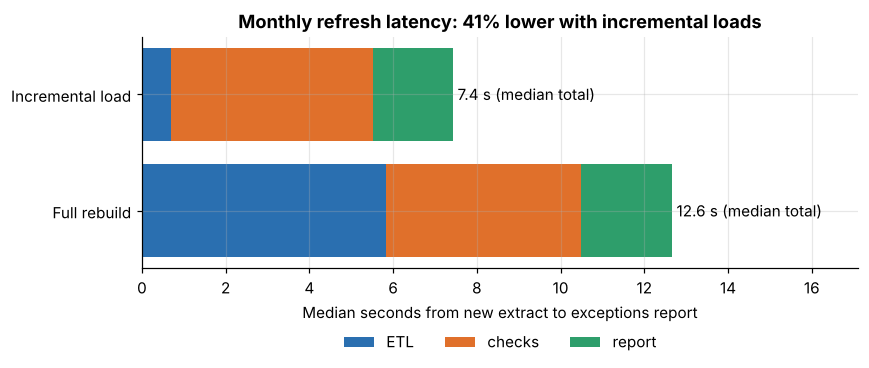

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
stages = ["etl_s", "checks_s", "report_s"]
left = np.zeros(2)
for s, c in zip(stages, ["#2a6fb0", "#e0702b", "#2e9e6b"]):
    vals = lat.loc[s, ["full_rebuild", "incremental"]].to_numpy()
    ax.barh(["Full rebuild", "Incremental load"], vals, left=left, color=c, label=s.replace("_s", "").upper() if s == "etl_s" else s.replace("_s", ""))
    left += vals
for i, col in enumerate(["full_rebuild", "incremental"]):
    ax.text(left[i] + 0.1, i, f"{lat.loc['total_s', col]:.1f} s (median total)", va="center")
ax.set_xlabel("Median seconds from new extract to exceptions report")
ax.set_title(f"Monthly refresh latency: {lat.loc['total_s', 'reduction']:.0%} lower with incremental loads")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False); ax.set_xlim(0, left.max() * 1.35)
plt.tight_layout(); plt.savefig(FIG / "03_refresh_latency.png"); plt.show()

In [11]:
shutil.rmtree(STAGE)
pd.DataFrame([{"automated_run_s": auto_s, "manual_baseline_min": MANUAL_BASELINE_MIN,
               "review_time_reduction": 1 - (auto_s / 60) / MANUAL_BASELINE_MIN,
               "full_rebuild_latency_s": lat.loc["total_s", "full_rebuild"],
               "incremental_latency_s": lat.loc["total_s", "incremental"],
               "latency_reduction": lat.loc["total_s", "reduction"]}]).round(4).to_csv(PROC / "run_timing.csv", index=False)

## Findings

* The automated cycle (extract, validate, load, nine checks, ranked report) produced an exceptions report of **6,067 transactions worth $49,963,530**, written to `data/processed/exceptions_report.csv`; 210 transactions fail two checks, and the top of the queue is duplicate payments that were also split purchases or went to brand-new vendors.
* **Review time:** the full automated run averaged **12.9 seconds (0.21 minutes)** over three runs (12.50, 12.24 and 13.83 s), against the 8-hour (480-minute) manual baseline, a **99.96% reduction** in the time to produce the review. The reviewer's time to work through the exceptions is not included and is not measured here. Every loaded transaction (417,470) is tested by all nine checks; no sampling.
* **Latency of the monthly refresh:** loading only the June 2025 extract (10,558 rows) incrementally instead of rebuilding from all three fiscal years cut the median time from extract to report from **12.6 s to 7.4 s, 41.1% lower**. The gain is all in the ETL stage (5.83 s to 0.69 s); the checks still scan the full history, which duplicate and vendor-outlier tests need. The incremental and full-rebuild reports are identical.
* By department, History (1,279 exceptions), Admissions (653), Human Resources (559) and Biomedical Engineering (532) lead the queue, driven by the six requesters whose amounts fail Benford's law.
* By dollars, vendor amount outliers ($20.3M) and new-vendor payments ($11.4M) carry the most value under review; duplicate payments ($1.9M) and self-approvals ($0.9M) are the most directly recoverable.